# DS201 - Lab 2: Mạng neural tích chập

Họ tên: Trần Yến Nhi
MSSV: 23521117

## 0. Chuẩn bị

In [29]:
%cd /content
!unzip -qo DS201_Lab2.zip
%cd /content/DS201_Lab2
!pip -q install -r requirements.txt

/content
/content/DS201_Lab2


In [30]:
import torch
print(torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

True Tesla T4


In [31]:
# để runs/ và splits/ trên drive, colab bị ngắt cũng không mất kết quả
from google.colab import drive
drive.mount("/content/drive")

SAVE_DIR = "/content/drive/MyDrive/DS201_Lab2"
!mkdir -p {SAVE_DIR}/runs {SAVE_DIR}/splits
!rm -rf runs splits
!ln -s {SAVE_DIR}/runs runs
!ln -s {SAVE_DIR}/splits splits
!ls runs

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
googlenet  lenet_avg  lenet_max  resnet18_aug


In [32]:
# tải dataset, resize trước rồi nén lại lên drive. mấy lần sau chỉ cần giải nén từ drive
import os

DATA = "VinaFood21_256"
ZIP = SAVE_DIR + "/VinaFood21_256.zip"

if not os.path.exists(DATA):
    if os.path.exists(ZIP):
        !unzip -q {ZIP}
    else:
        !gdown 1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR -O VinaFood21.zip
        !unzip -q VinaFood21.zip -d raw
        src = [root for root, dirs, _ in os.walk("raw") if "train" in dirs and "test" in dirs][0]
        !python prepare_data.py --src {src} --dst {DATA}
        !zip -qr {ZIP} {DATA}
        !rm -rf raw VinaFood21.zip

In [33]:
import pandas as pd

classes = sorted(os.listdir(f"{DATA}/train"))
count = pd.DataFrame({
    "train": [len(os.listdir(f"{DATA}/train/{c}")) for c in classes],
    "test": [len(os.listdir(f"{DATA}/test/{c}")) for c in classes],
}, index=classes)
print("tổng train:", count.train.sum(), "| tổng test:", count.test.sum())
count.sort_values("train")

tổng train: 10044 | tổng test: 6682


,train,test
bap-nuong,215,143
ca-ri,258,171
banh-u,266,176
canh-khoai-mo,296,198
tau-hu,304,203
hoanh-thanh-nuoc,361,240
banh-can,363,241
bot-chien,415,276
banh-mi-chao,434,289
canh-kho-qua,436,290


In [34]:
import json
from IPython.display import Image, display


def run(name, args):
    if os.path.exists(f"runs/{name}/test_metrics.json"):
        print(name, "đã chạy rồi")
        return
    !python train.py {args} --run_name {name} --data_root {DATA}
    !python evaluate.py --run_dir runs/{name} --data_root {DATA}


def show(name):
    info = json.load(open(f"runs/{name}/info.json"))
    m = json.load(open(f"runs/{name}/test_metrics.json"))
    print(f"params {info['n_params']:,} | {info['sec_per_epoch']:.1f}s/epoch | best epoch {info['best_epoch']}")
    print(f"accuracy {m['accuracy']:.4f} | precision {m['precision']:.4f} | recall {m['recall']:.4f} | f1 {m['f1']:.4f}")
    display(Image(f"runs/{name}/loss.png", width=450))
    display(Image(f"runs/{name}/confusion_matrix.png", width=650))


def f1_table(*names):
    cols = [pd.read_csv(f"runs/{n}/per_class_f1.csv", index_col="class")["f1"].rename(n) for n in names]
    return pd.concat(cols, axis=1).sort_values(names[0])

## 1. Kiểm tra kiến trúc

In [35]:
import torch.nn as nn
from models import LeNet5, GoogLeNet, ResNet18, PretrainedResnet, count_params

lenet = LeNet5(3, 64, 21)
x = torch.zeros(1, 3, 64, 64)
for name in ["c1", "s2", "c3", "s4", "flatten", "f5", "f6", "out"]:
    if name == "flatten":
        x = x.flatten(1)
        print(name, tuple(x.shape))
        continue
    layer = getattr(lenet, name)
    x = layer(x)
    print(name, tuple(x.shape), count_params(layer))
print("tổng:", count_params(lenet))

c1 (1, 6, 60, 60) 456
s2 (1, 6, 30, 30) 0
c3 (1, 16, 26, 26) 2416
s4 (1, 16, 13, 13) 0
flatten (1, 2704)
f5 (1, 120) 324600
f6 (1, 84) 10164
out (1, 21) 1785
tổng: 339421


In [36]:
net = GoogLeNet(21)
tinh_tay = {"inc3a": 32 + 64 + 16 + 16, "inc3b": 64 + 96 + 48 + 32,
            "inc4a": 96 + 104 + 24 + 32, "inc4b": 80 + 112 + 32 + 32}

x = net.stem(torch.zeros(1, 3, 64, 64))
print("stem", tuple(x.shape))
for name in ["inc3a", "inc3b", "pool", "inc4a", "inc4b"]:
    x = getattr(net, name)(x)
    if name in tinh_tay:
        print(f"{name}: tính tay {tinh_tay[name]}, code {x.shape[1]}, shape {tuple(x.shape)}, "
              f"params {count_params(getattr(net, name)):,}")
print("tổng:", count_params(net), "| fc:", count_params(net.fc))

stem (1, 96, 16, 16)
inc3a: tính tay 128, code 128, shape (1, 128, 16, 16), params 41,016
inc3b: tính tay 240, code 240, shape (1, 240, 16, 16), params 97,344
inc4a: tính tay 256, code 256, shape (1, 256, 8, 8), params 94,200
inc4b: tính tay 256, code 256, shape (1, 256, 8, 8), params 112,452
tổng: 411977 | fc: 5397


In [37]:
r18 = ResNet18(21)
x = torch.zeros(1, 3, 112, 112)
for name in ["stem", "layer1", "layer2", "layer3", "layer4"]:
    x = getattr(r18, name)(x)
    print(name, tuple(x.shape), count_params(getattr(r18, name)))
print("tổng:", count_params(r18))

from torchvision.models import resnet18
tv = resnet18()
tv.fc = nn.Linear(512, 21)
print("torchvision:", count_params(tv))

stem (1, 64, 28, 28) 9536
layer1 (1, 64, 28, 28) 147968
layer2 (1, 128, 14, 14) 525568
layer3 (1, 256, 7, 7) 2099712
layer4 (1, 512, 4, 4) 8393728
tổng: 11187285
torchvision: 11187285


In [38]:
fe = PretrainedResnet(21, freeze_backbone=True)
ft = PretrainedResnet(21, freeze_backbone=False)
print("feature extraction:", count_params(fe), "| học:", count_params(fe, trainable=True))
print("fine-tuning:", count_params(ft), "| học:", count_params(ft, trainable=True))
del fe, ft

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

feature extraction: 23551061 | học: 43029
fine-tuning: 23551061 | học: 23551061


## Bài 1. LeNet-5

Ảnh 64x64, ReLU, AvgPool2d(2, 2), Adam lr 1e-3, batch 32, 20 epoch. Sau đó đổi sang MaxPool2d, còn lại giữ nguyên.

In [39]:
run("lenet_avg", "--model lenet --pool avg")

lenet_avg đã chạy rồi


params 339,421 | 17.4s/epoch | best epoch 15
accuracy 0.2983 | precision 0.3087 | recall 0.2896 | f1 0.2849


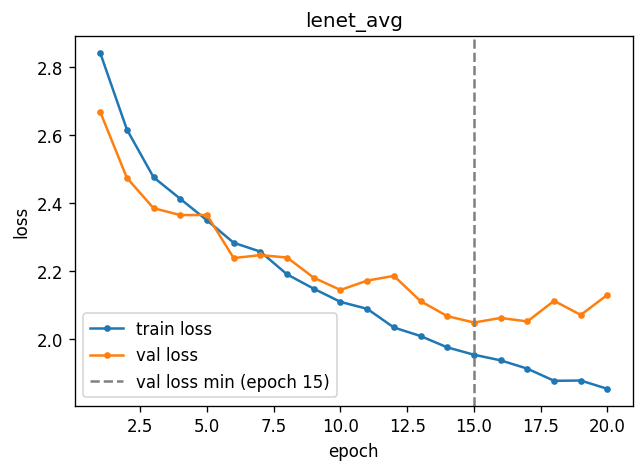

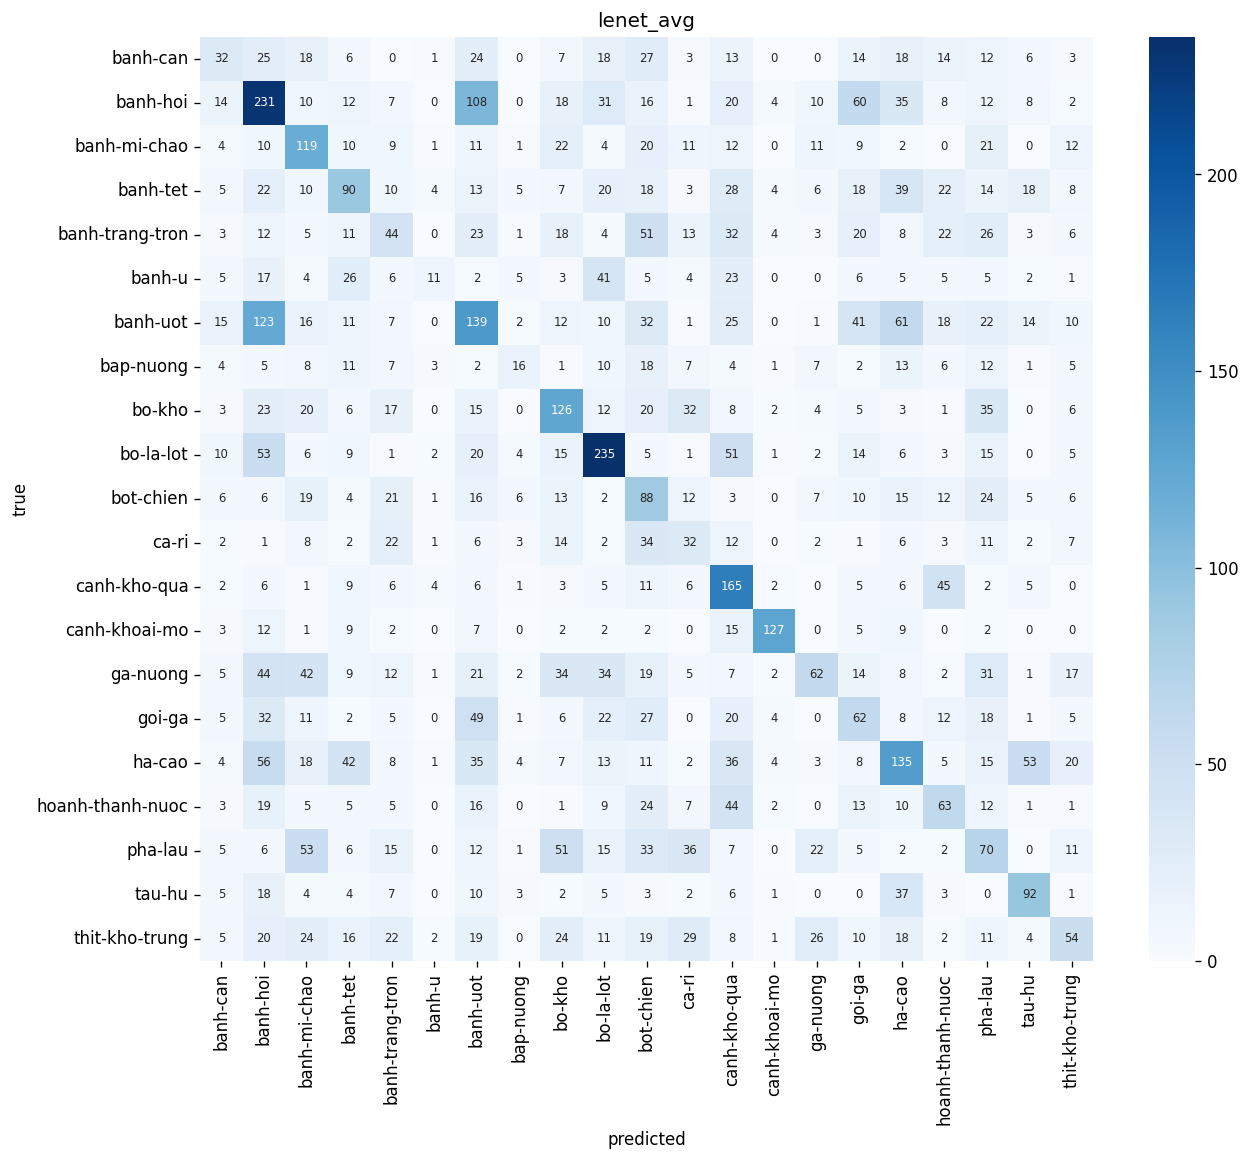

In [40]:
show("lenet_avg")

In [41]:
run("lenet_max", "--model lenet --pool max")

lenet_max đã chạy rồi


params 339,421 | 17.1s/epoch | best epoch 19
accuracy 0.3185 | precision 0.3173 | recall 0.3081 | f1 0.2979


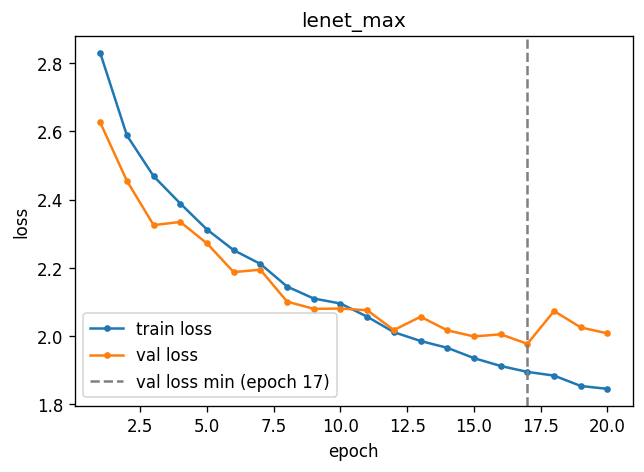

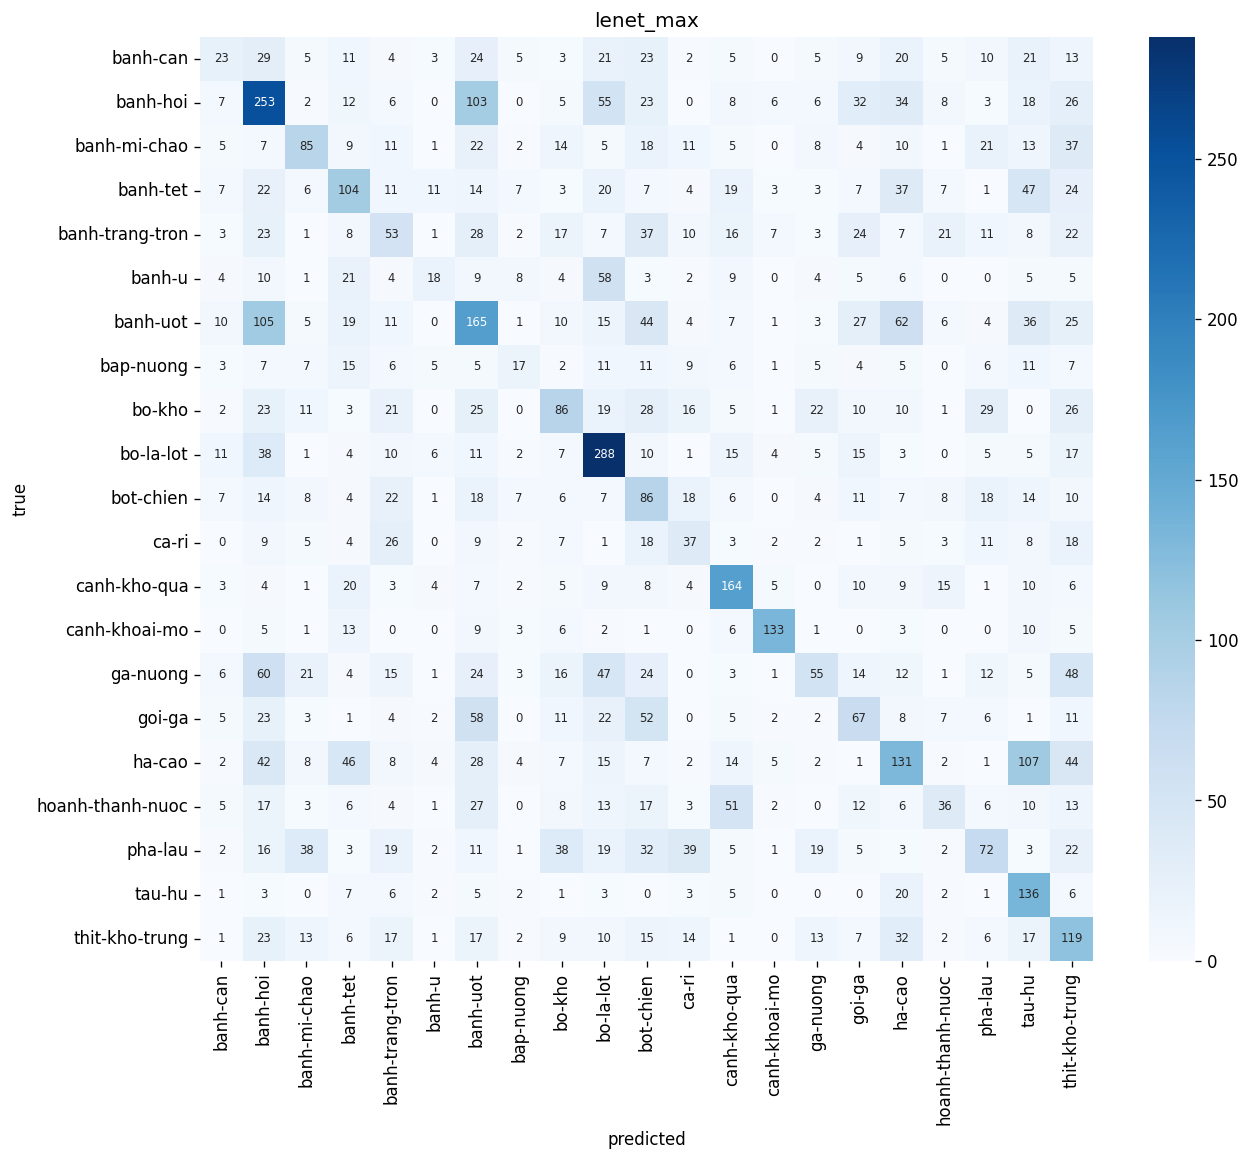

In [42]:
show("lenet_max")

In [43]:
f1_table("lenet_avg", "lenet_max")

,lenet_avg,lenet_max
class,,
banh-u,0.1058,0.1506
bap-nuong,0.1616,0.1596
banh-trang-tron,0.1624,0.1860
banh-can,0.1680,0.1322
ca-ri,0.1693,0.2114
pha-lau,0.1939,0.2500
goi-ga,0.2026,0.2414
thit-kho-trung,0.2139,0.2871
ga-nuong,0.2305,0.2060


Nhận xét:
- Số tham số 339,421, đúng với tính tay. F5 chiếm 324,600 (khoảng 95.6%), 2 lớp conv chỉ có 2,872. Pooling không có tham số nên đổi Avg sang Max không đổi số tham số.
- AvgPool: accuracy 0.2983, macro-F1 0.2849. MaxPool: accuracy 0.3185, macro-F1 0.2979, cao hơn khoảng 0.013 (13/21 lớp tăng). MaxPool giữ lại giá trị lớn nhất trong mỗi ô 2x2 nên giữ được cạnh, kết cấu rõ hơn, còn AvgPool lấy trung bình nên làm mờ đi. Tuy vậy chênh lệch nhỏ và em chỉ chạy 1 seed nên chưa thể khẳng định MaxPool chắc chắn tốt hơn.
- Loss: train loss giảm đều nhưng chậm, sau 20 epoch train acc mới khoảng 42% → model đang underfit, LeNet quá nhỏ (2 lớp conv với 6 và 16 filter) để phân biệt 21 món từ ảnh 64x64. Val loss của bản AvgPool thấp nhất ở epoch 15 (2.047) rồi nhích lên 2.129 ở epoch 20, bắt đầu hơi overfit; bản MaxPool val loss thấp nhất ở epoch 17.
- Lớp F1 thấp nhất (AvgPool): banh-u 0.106, bap-nuong 0.162, banh-trang-tron 0.162, banh-can 0.168, ca-ri 0.169. Cao nhất là canh-khoai-mo 0.712, chắc do màu tím rất dễ nhận ra. Trên confusion matrix, nhầm nhiều nhất là banh-uot → banh-hoi (123 ảnh) và banh-hoi → banh-uot (108 ảnh): hai món đều làm từ bột gạo màu trắng, ở 64x64 nhìn gần như giống nhau.

## Bài 2. GoogLeNet rút gọn

4 Inception block (inc3a, inc3b, inc4a, inc4b), số channel khoảng 1/2 bản gốc. Ảnh 64x64 nên stem chỉ giảm còn 16x16, giữa inc3b và inc4a có thêm 1 maxpool xuống 8x8. Nối nhánh bằng `torch.cat(..., dim=1)`, cuối mạng dùng `AdaptiveAvgPool2d(1)` thay Flatten. Từ bài này em bật `--amp` cho nhanh, các thông số khác giữ như Bài 1.

In [44]:
run("googlenet", "--model googlenet --amp")

googlenet đã chạy rồi


params 411,977 | 20.4s/epoch | best epoch 20
accuracy 0.4600 | precision 0.4649 | recall 0.4429 | f1 0.4382


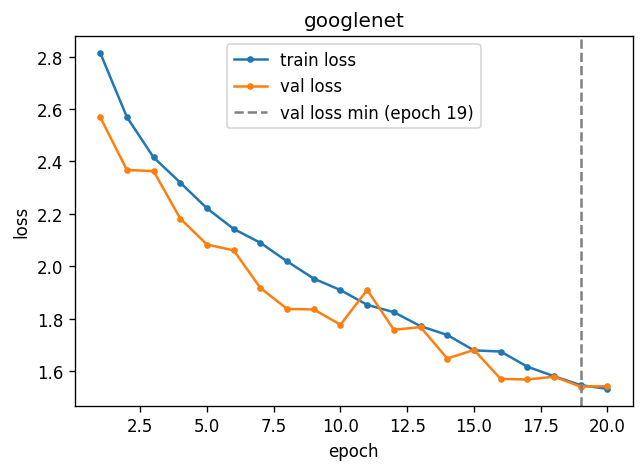

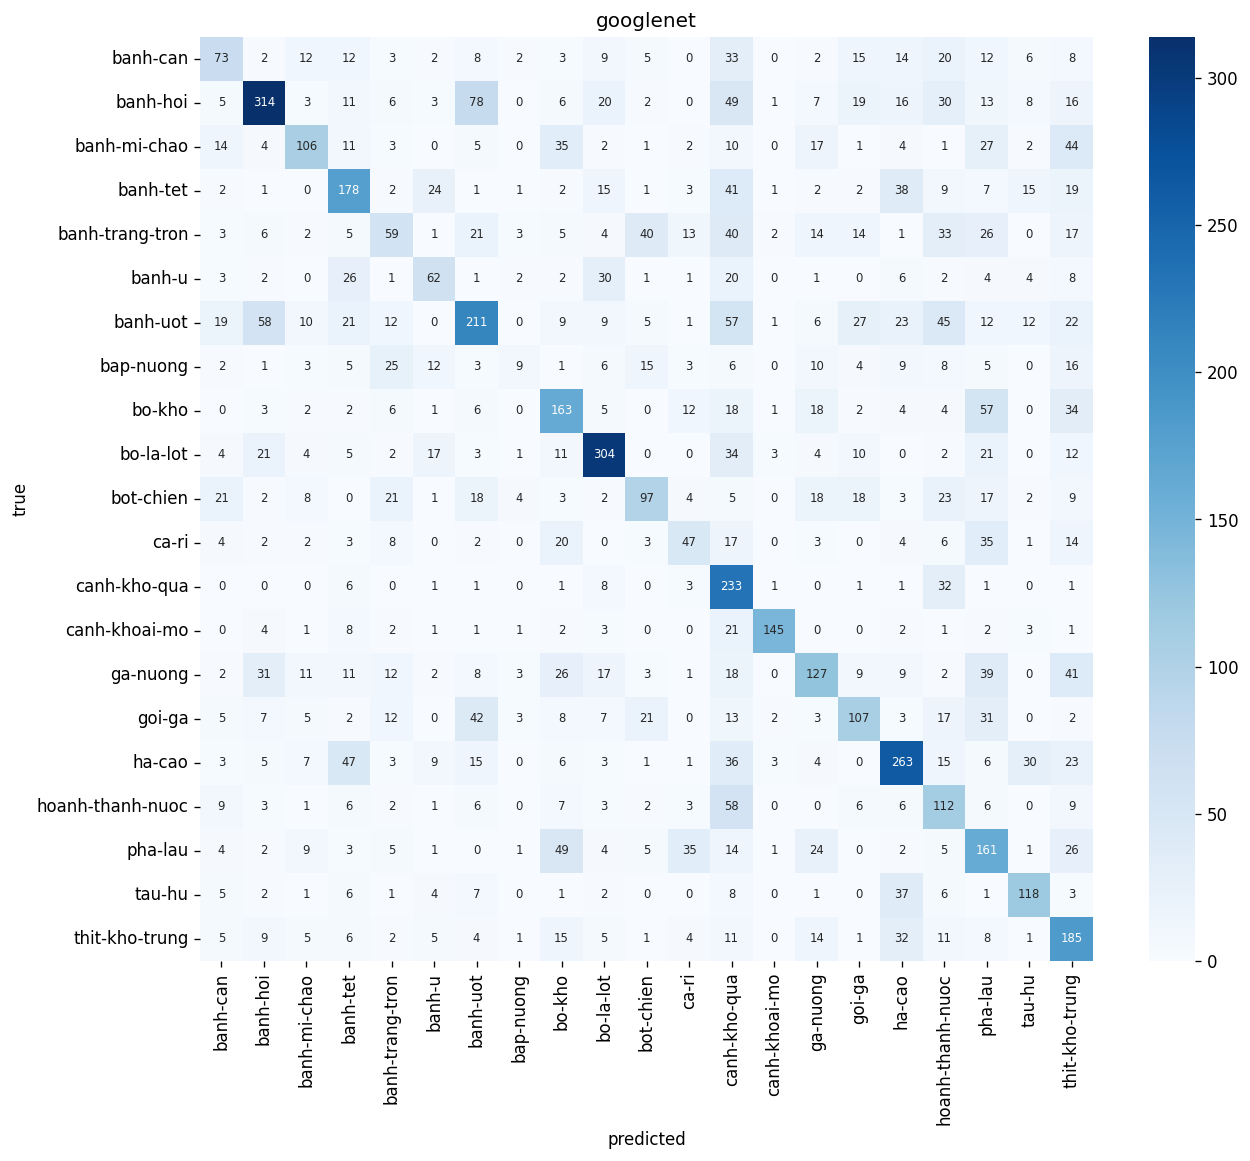

In [45]:
show("googlenet")

In [46]:
rows = []
for name in ["lenet_avg", "lenet_max", "googlenet"]:
    info = json.load(open(f"runs/{name}/info.json"))
    m = json.load(open(f"runs/{name}/test_metrics.json"))
    rows.append([name, info["n_params"], round(info["sec_per_epoch"], 1), round(m["accuracy"], 4), round(m["f1"], 4)])
pd.DataFrame(rows, columns=["model", "params", "s/epoch", "accuracy", "macro-F1"])

,model,params,s/epoch,accuracy,macro-F1
0,lenet_avg,339421,17.4,0.2983,0.2849
1,lenet_max,339421,17.1,0.3185,0.2979
2,googlenet,411977,20.4,0.4600,0.4382


In [47]:
f1_table("googlenet", "lenet_avg")

,googlenet,lenet_avg
class,,
bap-nuong,0.1034,0.1616
banh-trang-tron,0.2379,0.1624
ca-ri,0.3092,0.1693
banh-can,0.3443,0.1680
hoanh-thanh-nuoc,0.3590,0.2582
pha-lau,0.3820,0.1939
banh-u,0.3839,0.1058
ga-nuong,0.3926,0.2305
bot-chien,0.4050,0.2319


Nhận xét:
- Channel ra của 4 block tính tay và in từ code khớp nhau: 128, 240, 256, 256.
- Tổng 411,977 tham số, chỉ nhiều hơn LeNet khoảng 21%, nhưng phân bố khác hẳn: 4 Inception block chiếm 345,012, stem 61,568, còn lớp fc chỉ có 5,397 nhờ GAP. Nếu flatten 8x8x256 thì riêng lớp này đã cần 344,085, bằng cả LeNet.
- Thời gian 20.4 s/epoch so với 17.4 s của LeNet. GoogLeNet tính toán nhiều hơn LeNet rất nhiều nhưng thời gian gần như nhau, vì phần chậm nhất là đọc ảnh + augment trên 2 CPU của Colab, GPU phải chờ dữ liệu. Ở Bài 3 thấy rõ hơn: cùng ResNet-18, tắt augmentation thì từ 30.8 xuống còn 21.1 s/epoch.
- macro-F1 0.4382 so với 0.2849 của LeNet (tăng 0.153), accuracy 0.4600 so với 0.2983. 20/21 lớp tăng, chỉ có bap-nuong giảm (0.162 → 0.103); đây là lớp ít ảnh nhất (215 ảnh train) và hay bị đoán thành banh-trang-tron. Ngoài ra khá nhiều lớp bị đoán nhầm thành canh-kho-qua (cột canh-kho-qua trên confusion matrix đậm).
- GoogLeNet tốt hơn vì nhiều filter hơn hẳn, mỗi block nhìn ảnh ở nhiều kích thước kernel (1x1, 3x3, 5x5) cùng lúc, stem có BatchNorm nên train ổn định hơn. Model vẫn chưa hội tụ: val loss còn giảm tới epoch 19-20, checkpoint tốt nhất là epoch cuối (20), train acc mới 52% → train thêm epoch có thể còn tăng.

## Bài 3. ResNet-18 train từ đầu

[2, 2, 2, 2] BasicBlock, shortcut identity khi cùng shape, conv 1x1 + BN khi đổi channel/stride. Ảnh 112x112 (64x64 thì tới layer4 chỉ còn 2x2), 30 epoch, chạy có và không có augmentation.

In [51]:
run("resnet18_aug", "--model resnet18 --amp")

resnet18_aug | cuda | train 9040 ảnh | val 1004 ảnh
params 11,187,285 (trainable 11,187,285) | img 112 | lr 0.001 | aug True
train tiếp từ epoch 4
epoch 4/30 - train loss 2.2332 acc 0.3094 - val loss 2.1732 acc 0.3018 f1 0.2763 - 28s
epoch 5/30 - train loss 2.1237 acc 0.3483 - val loss 2.6382 acc 0.2918 f1 0.2719 - 32s
epoch 6/30 - train loss 2.0328 acc 0.3733 - val loss 2.0666 acc 0.3436 f1 0.2660 - 30s
epoch 7/30 - train loss 1.9579 acc 0.3916 - val loss 2.1624 acc 0.3466 f1 0.3139 - 30s
epoch 8/30 - train loss 1.8842 acc 0.4100 - val loss 1.8222 acc 0.4153 f1 0.3675 - 31s
epoch 9/30 - train loss 1.7971 acc 0.4388 - val loss 1.8145 acc 0.4382 f1 0.3940 - 31s
epoch 10/30 - train loss 1.7294 acc 0.4552 - val loss 1.8736 acc 0.4104 f1 0.3785 - 32s
epoch 11/30 - train loss 1.6620 acc 0.4706 - val loss 1.7912 acc 0.4592 f1 0.4152 - 30s
epoch 12/30 - train loss 1.5894 acc 0.4990 - val loss 1.7028 acc 0.4631 f1 0.4302 - 32s
epoch 13/30 - train loss 1.5415 acc 0.5083 - val loss 1.6237 acc 0.

params 11,187,285 | 30.8s/epoch | best epoch 27
accuracy 0.5296 | precision 0.5502 | recall 0.5202 | f1 0.5271


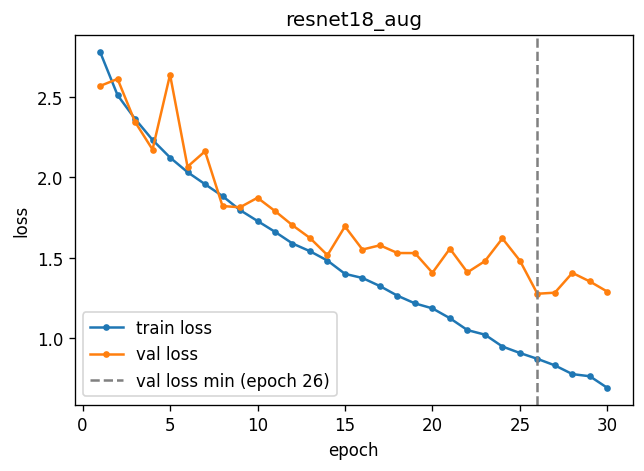

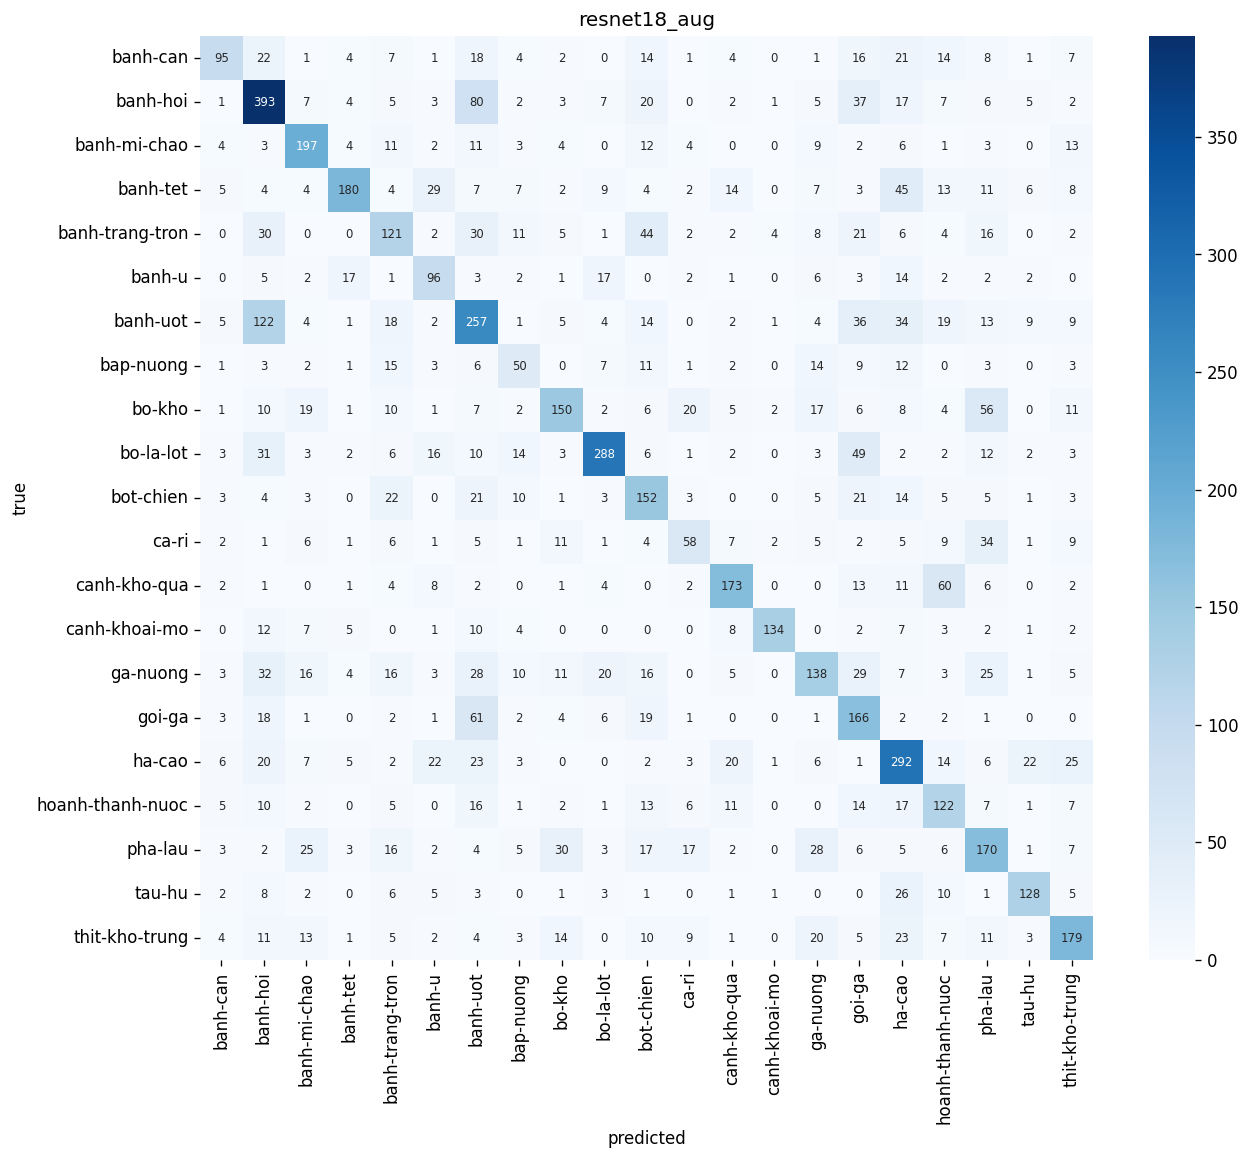

In [52]:
show("resnet18_aug")

In [53]:
run("resnet18_noaug", "--model resnet18 --no_aug --amp")

resnet18_noaug | cuda | train 9040 ảnh | val 1004 ảnh
params 11,187,285 (trainable 11,187,285) | img 112 | lr 0.001 | aug False
epoch 1/30 - train loss 2.6754 acc 0.1949 - val loss 2.8316 acc 0.1892 f1 0.1454 - 19s
epoch 2/30 - train loss 2.3844 acc 0.2669 - val loss 2.2443 acc 0.3078 f1 0.2572 - 19s
epoch 3/30 - train loss 2.2051 acc 0.3165 - val loss 2.2395 acc 0.3058 f1 0.2435 - 20s
epoch 4/30 - train loss 2.0124 acc 0.3659 - val loss 2.6370 acc 0.2699 f1 0.2097 - 21s
epoch 5/30 - train loss 1.8736 acc 0.4118 - val loss 2.2673 acc 0.2998 f1 0.2660 - 21s
epoch 6/30 - train loss 1.6963 acc 0.4611 - val loss 1.9752 acc 0.4094 f1 0.3717 - 21s
epoch 7/30 - train loss 1.5341 acc 0.5140 - val loss 3.0568 acc 0.2918 f1 0.2607 - 22s
epoch 8/30 - train loss 1.3582 acc 0.5637 - val loss 1.9161 acc 0.4163 f1 0.3846 - 21s
epoch 9/30 - train loss 1.1428 acc 0.6303 - val loss 1.8976 acc 0.4671 f1 0.4314 - 20s
epoch 10/30 - train loss 0.9072 acc 0.7034 - val loss 1.9317 acc 0.4552 f1 0.4465 - 22s
e

params 11,187,285 | 21.1s/epoch | best epoch 29
accuracy 0.4572 | precision 0.4545 | recall 0.4341 | f1 0.4333


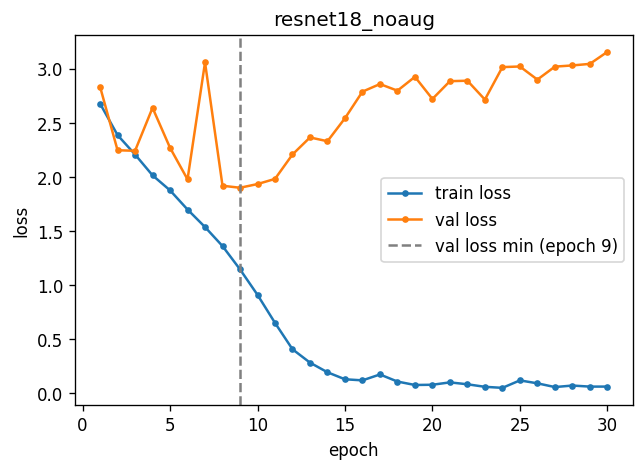

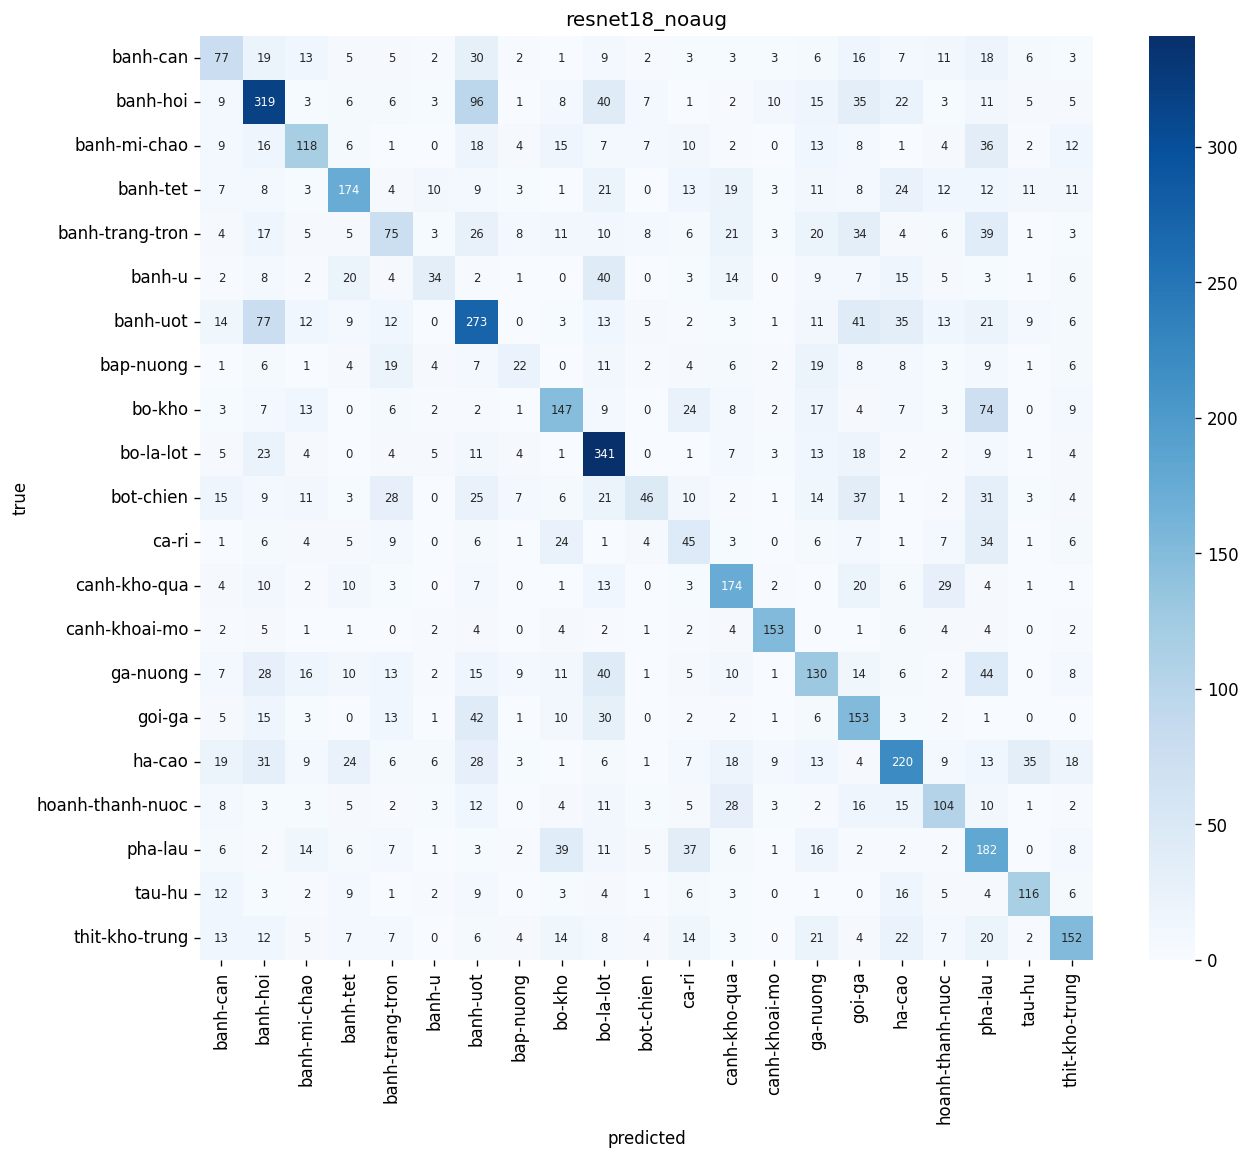

In [55]:
show("resnet18_noaug")

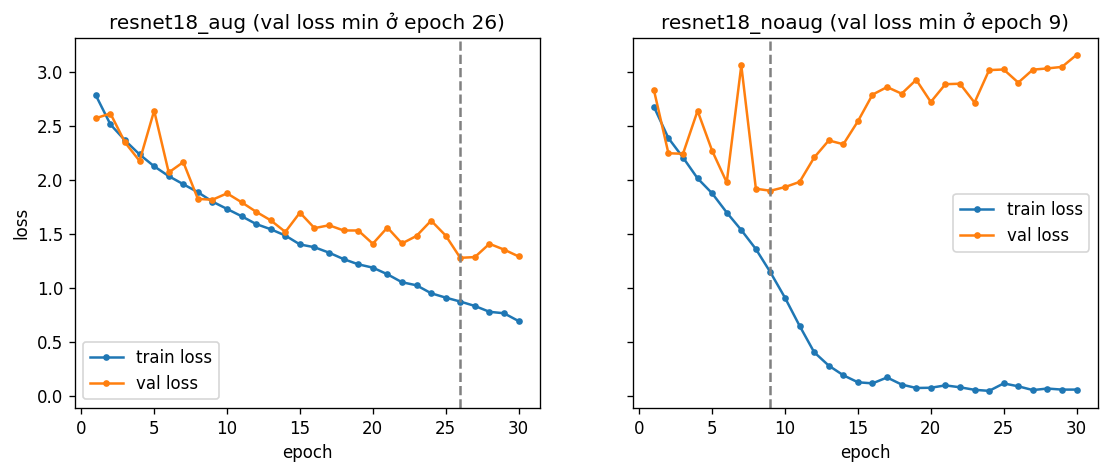

In [56]:
!python summary.py > /dev/null
display(Image("runs/resnet18_compare.png"))

Nhận xét:
- Số tham số 11,187,285, khớp với resnet18 của torchvision khi đổi fc sang 21 lớp.
- Có aug: accuracy 0.5296, macro-F1 0.5271. Không aug: accuracy 0.4572, macro-F1 0.4333 → có aug cao hơn 0.0938, 20/21 lớp tăng.
- Không aug: val loss thấp nhất ở epoch 9 (1.898), từ khoảng epoch 9-10 hai đường loss tách nhau rõ: train loss giảm gần về 0 (0.059 ở epoch 30, train acc 98%) còn val loss tăng lên 3.15, val acc đứng quanh 50% → overfit nặng, model học thuộc tập train. Val F1 vẫn dao động quanh 0.44-0.51 dù val loss tăng từ 1.9 lên 3.15: số ảnh đoán đúng gần như không đổi, nhưng các ảnh đoán sai thì model đoán rất tự tin nên loss tăng mạnh.
- Có aug: hai đường đi sát nhau tới khoảng epoch 15, sau đó khoảng cách mới tăng dần (epoch 30: train 0.69, val 1.29). Val loss thấp nhất ở epoch 26 (1.277) và nhìn chung vẫn đang giảm, train acc 77% → chưa overfit nặng, train thêm epoch có thể còn tăng.
- Giải thích: ResNet-18 có 11.2 triệu tham số mà chỉ có 9,040 ảnh train, gấp 33 lần LeNet, nên rất dễ học thuộc. Không aug thì mỗi epoch thấy lại đúng các ảnh cũ; có aug (cắt, lật, xoay, đổi sáng) thì mỗi epoch ảnh lại khác đi một chút, model phải học đặc trưng chung hơn. Đổi lại train chậm hơn (30.8 so với 21.1 s/epoch) và cần nhiều epoch hơn mới hội tụ.
- ResNet-18 không aug (0.4333) chỉ ngang GoogLeNet (0.4382) dù nhiều tham số gấp 27 lần và ảnh to hơn (112 so với 64) → thêm tham số mà không đủ dữ liệu hoặc không có regularization thì không giúp được nhiều.

## Bài 4. ResNet-50 pretrained

`microsoft/resnet-50`, bỏ classifier 1000 lớp, thay bằng `nn.Linear(2048, 21)`. Ảnh 224x224, mean/std của ImageNet, 10 epoch.
- Feature extraction: đóng băng backbone, chỉ học classifier, lr 1e-3
- Fine-tuning: học toàn bộ, lr 1e-4

In [57]:
run("resnet50_fe", "--model resnet50 --mode fe --amp")

Loading weights: 100% 320/320 [00:00<00:00, 4480.96it/s]
resnet50_fe | cuda | train 9040 ảnh | val 1004 ảnh
params 23,551,061 (trainable 43,029) | img 224 | lr 0.001 | aug True
epoch 1/10 - train loss 2.1307 acc 0.4441 - val loss 1.6180 acc 0.6056 f1 0.5967 - 50s
epoch 2/10 - train loss 1.4144 acc 0.6427 - val loss 1.2643 acc 0.6783 f1 0.6670 - 49s
epoch 3/10 - train loss 1.1670 acc 0.6936 - val loss 1.0854 acc 0.7301 f1 0.7216 - 48s
epoch 4/10 - train loss 1.0325 acc 0.7189 - val loss 1.0019 acc 0.7181 f1 0.7150 - 50s
epoch 5/10 - train loss 0.9401 acc 0.7393 - val loss 0.9256 acc 0.7480 f1 0.7443 - 49s
epoch 6/10 - train loss 0.8722 acc 0.7584 - val loss 0.8744 acc 0.7580 f1 0.7546 - 50s
epoch 7/10 - train loss 0.8230 acc 0.7741 - val loss 0.8386 acc 0.7540 f1 0.7530 - 49s
epoch 8/10 - train loss 0.7774 acc 0.7759 - val loss 0.8209 acc 0.7620 f1 0.7616 - 49s
epoch 9/10 - train loss 0.7400 acc 0.7897 - val loss 0.7837 acc 0.7649 f1 0.7631 - 49s
epoch 10/10 - train loss 0.7148 acc 0.79

params 23,551,061 | 49.2s/epoch | best epoch 10
accuracy 0.7264 | precision 0.7469 | recall 0.7327 | f1 0.7303


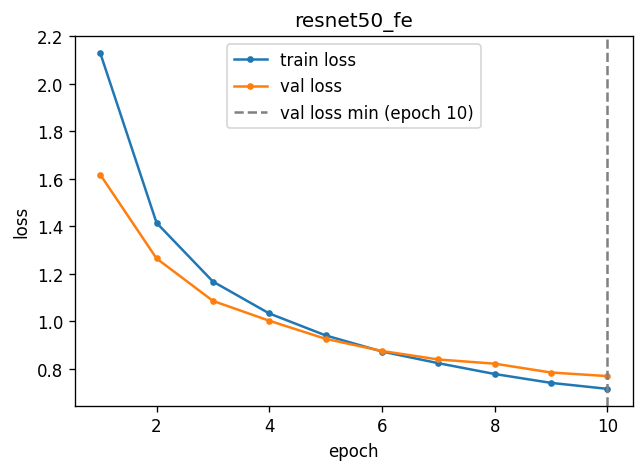

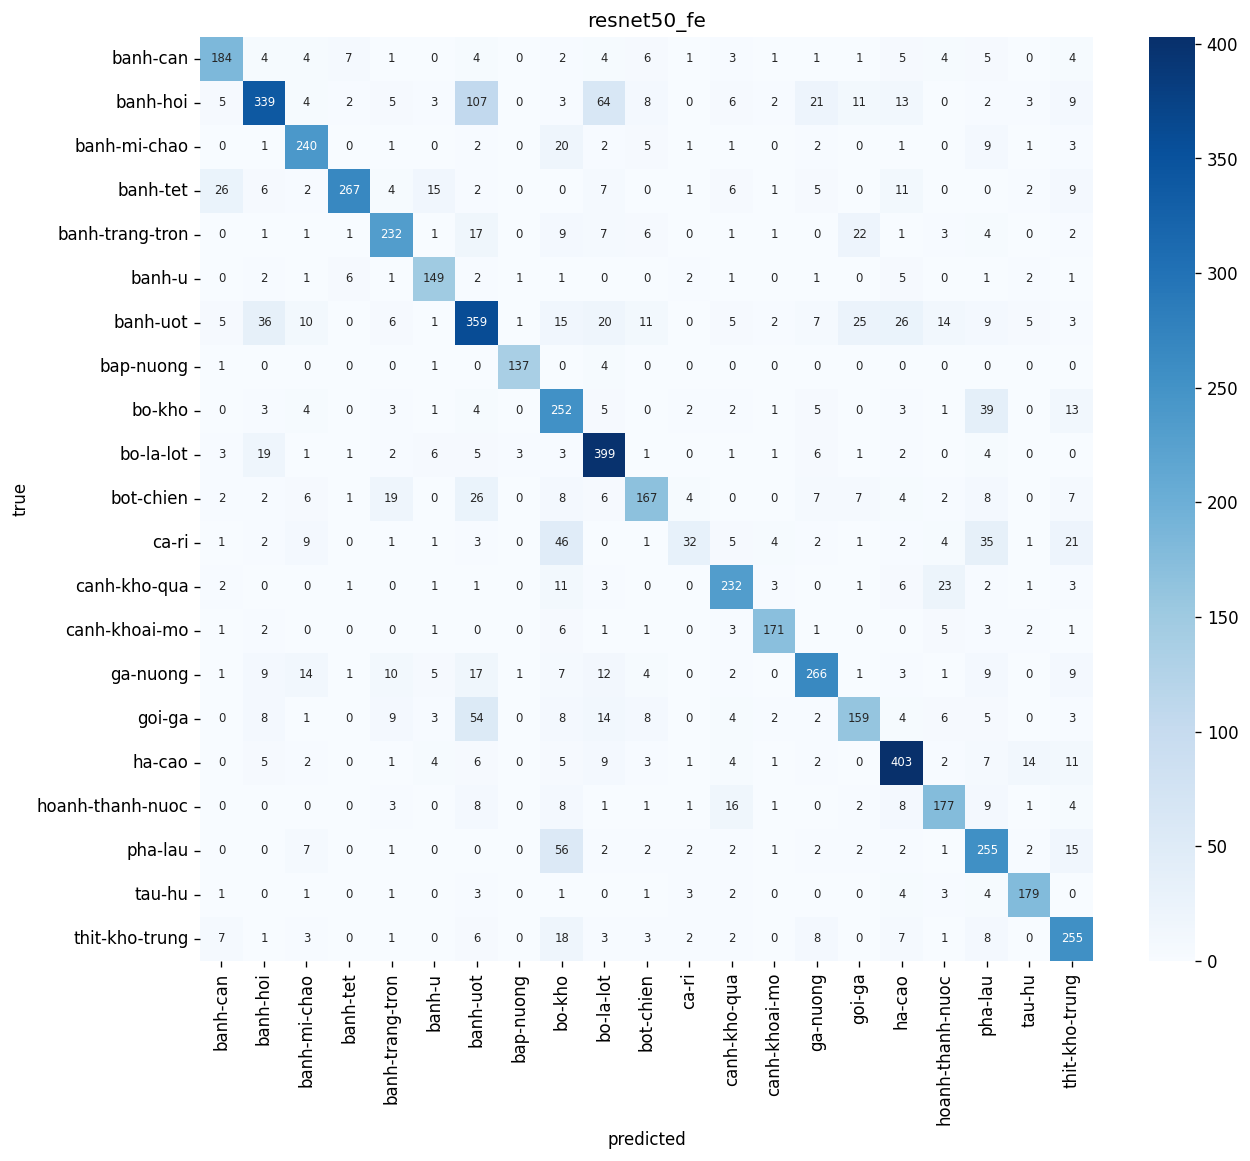

In [58]:
show("resnet50_fe")

In [59]:
run("resnet50_ft", "--model resnet50 --mode ft --amp")

Loading weights: 100% 320/320 [00:00<00:00, 4377.46it/s]
resnet50_ft | cuda | train 9040 ảnh | val 1004 ảnh
params 23,551,061 (trainable 23,551,061) | img 224 | lr 0.0001 | aug True
epoch 1/10 - train loss 2.7411 acc 0.1793 - val loss 2.2950 acc 0.4552 f1 0.3452 - 57s
epoch 2/10 - train loss 1.6696 acc 0.5593 - val loss 1.0971 acc 0.6853 f1 0.6550 - 59s
epoch 3/10 - train loss 0.9746 acc 0.7200 - val loss 0.7158 acc 0.7878 f1 0.7705 - 65s
epoch 4/10 - train loss 0.7087 acc 0.7804 - val loss 0.5872 acc 0.8147 f1 0.7988 - 66s
epoch 5/10 - train loss 0.5584 acc 0.8290 - val loss 0.4988 acc 0.8446 f1 0.8296 - 65s
epoch 6/10 - train loss 0.4645 acc 0.8576 - val loss 0.4519 acc 0.8655 f1 0.8522 - 66s
epoch 7/10 - train loss 0.4107 acc 0.8723 - val loss 0.4040 acc 0.8685 f1 0.8587 - 65s
epoch 8/10 - train loss 0.3367 acc 0.8967 - val loss 0.3778 acc 0.8795 f1 0.8712 - 66s
epoch 9/10 - train loss 0.2950 acc 0.9063 - val loss 0.4020 acc 0.8725 f1 0.8618 - 65s
epoch 10/10 - train loss 0.2581 acc

params 23,551,061 | 64.2s/epoch | best epoch 8
accuracy 0.8456 | precision 0.8497 | recall 0.8447 | f1 0.8454


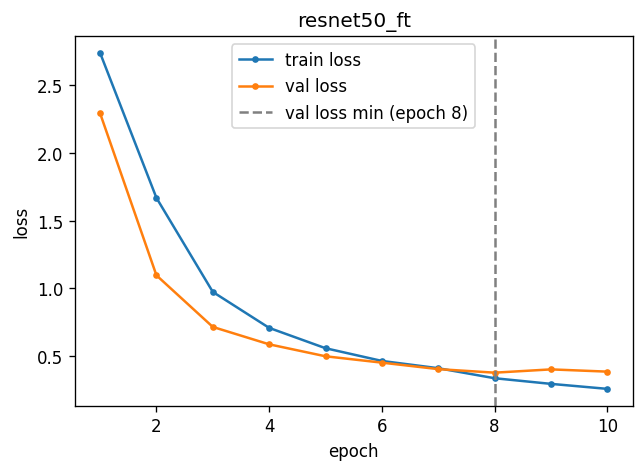

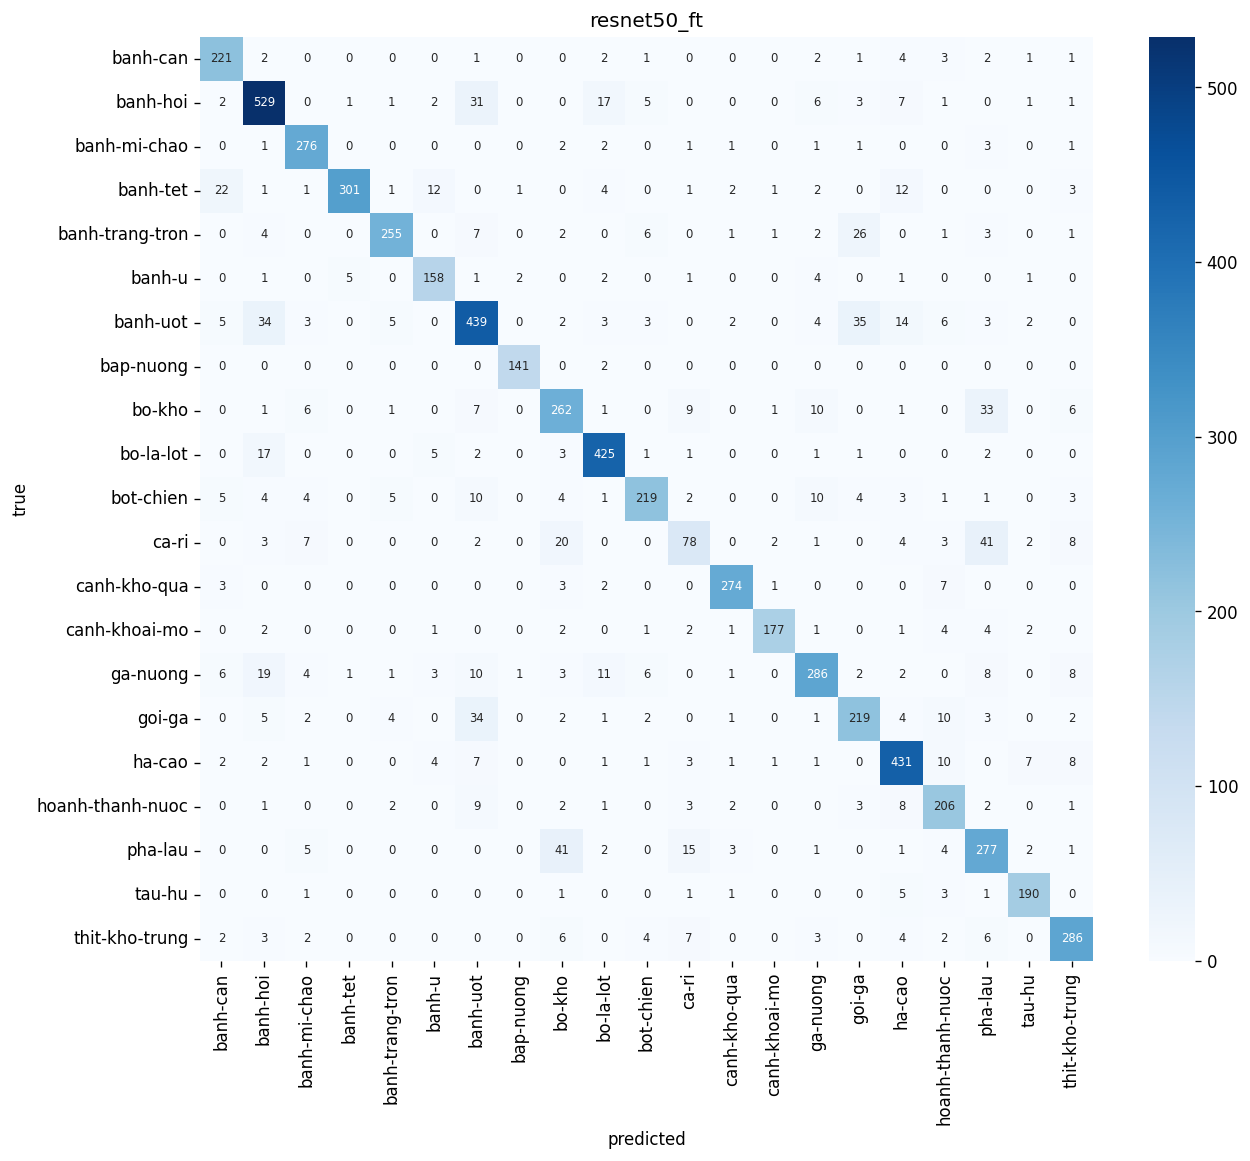

In [60]:
show("resnet50_ft")

Nhận xét:
- Feature extraction: accuracy 0.7264, macro-F1 0.7303, 49.2 s/epoch, chỉ học 43,029 tham số. Ngay epoch 1 val acc đã 60.6%, cao hơn LeNet và GoogLeNet sau 20 epoch, gần bằng ResNet-18 có aug sau 30 epoch (64.5%). Val loss tới epoch 10 vẫn còn giảm nên thêm epoch có thể còn tăng chút.
- Fine-tuning: accuracy 0.8456, macro-F1 0.8454, 64.2 s/epoch, cao hơn feature extraction 0.115 và cả 21 lớp đều tăng. Val loss thấp nhất ở epoch 8 (0.378) rồi nhích lên → bắt đầu overfit nhẹ, checkpoint lấy ở epoch 8.
- Feature extraction chỉ nhanh hơn fine-tuning khoảng 15 s/epoch vì vẫn phải forward qua toàn bộ backbone, chỉ bỏ được phần backward của backbone.
- So với ResNet-18 train từ đầu (có aug, 0.5271): fine-tuning cao hơn 0.318, feature extraction cao hơn 0.203. Lớp khó nhất vẫn là ca-ri (fine-tuning 0.529, feature extraction chỉ 0.287 với recall 0.187), hay bị nhầm sang bo-kho và pha-lau, ba món đều là thịt trong nước sốt màu nâu đỏ. bap-nuong từ 0.360 (ResNet-18) lên 0.979.
- Giải thích: backbone đã được train trên ImageNet (khoảng 1.2 triệu ảnh, 1000 lớp, có cả một số lớp đồ ăn) nên các đặc trưng từ cạnh, kết cấu tới hình dạng đã có sẵn, chỉ cần học thêm cách phân biệt 21 món. ResNet-18 từ đầu phải học mọi thứ từ khoảng 9 nghìn ảnh nên vừa chậm vừa overfit. Fine-tuning tốt hơn feature extraction vì các layer sâu được chỉnh lại theo ảnh món ăn Việt Nam, lr nhỏ (1e-4) nên không phá hỏng trọng số pretrained.

## Bảng tổng hợp

In [63]:
!python summary.py > /dev/null
from IPython.display import Markdown
display(Markdown(open("results.md").read()))

## Bảng tổng hợp (tập test)

| Mô hình | Resize | Tham số | Tham số học | Giây/epoch | Accuracy | Precision | Recall | macro-F1 |
|---|---|---|---|---|---|---|---|---|
| LeNet-5 (AvgPool) | 64x64 | 339,421 | 339,421 | 17.4 | 0.2983 | 0.3087 | 0.2896 | 0.2849 |
| LeNet-5 (MaxPool) | 64x64 | 339,421 | 339,421 | 17.1 | 0.3185 | 0.3173 | 0.3081 | 0.2979 |
| GoogLeNet rút gọn | 64x64 | 411,977 | 411,977 | 20.4 | 0.4600 | 0.4649 | 0.4429 | 0.4382 |
| ResNet-18 từ đầu (có aug) | 112x112 | 11,187,285 | 11,187,285 | 30.8 | 0.5296 | 0.5502 | 0.5202 | 0.5271 |
| ResNet-18 từ đầu (không aug) | 112x112 | 11,187,285 | 11,187,285 | 21.1 | 0.4572 | 0.4545 | 0.4341 | 0.4333 |
| ResNet-50 pretrained (feature extraction) | 224x224 | 23,551,061 | 43,029 | 49.2 | 0.7264 | 0.7469 | 0.7327 | 0.7303 |
| ResNet-50 pretrained (fine-tuning) | 224x224 | 23,551,061 | 23,551,061 | 64.2 | 0.8456 | 0.8497 | 0.8447 | 0.8454 |

## So sánh macro-F1

- lenet_max vs lenet_avg: 0.2979 vs 0.2849 (chênh +0.0130)
- googlenet vs lenet_avg: 0.4382 vs 0.2849 (chênh +0.1533)
- resnet18_aug vs resnet18_noaug: 0.5271 vs 0.4333 (chênh +0.0938)
- resnet50_ft vs resnet50_fe: 0.8454 vs 0.7303 (chênh +0.1151)
- resnet50_ft vs resnet18_aug: 0.8454 vs 0.5271 (chênh +0.3183)

## Epoch val loss thấp nhất

| Run | Epoch | val loss min | val loss cuối |
|---|---|---|---|
| lenet_avg | 15 | 2.0473 | 2.1289 |
| lenet_max | 17 | 1.9767 | 2.0074 |
| googlenet | 19 | 1.5404 | 1.5420 |
| resnet18_aug | 26 | 1.2773 | 1.2903 |
| resnet18_noaug | 9 | 1.8976 | 3.1543 |
| resnet50_fe | 10 | 0.7685 | 0.7685 |
| resnet50_ft | 8 | 0.3778 | 0.3854 |

## F1 từng lớp

| Lớp | lenet_avg | lenet_max | googlenet | resnet18_aug | resnet18_noaug | resnet50_fe | resnet50_ft |
|---|---|---|---|---|---|---|---|
| banh-can | 0.168 | 0.132 | 0.344 | 0.488 | 0.332 | 0.767 | 0.868 |
| banh-hoi | 0.343 | 0.378 | 0.578 | 0.583 | 0.518 | 0.648 | 0.856 |
| banh-mi-chao | 0.344 | 0.331 | 0.441 | 0.646 | 0.443 | 0.801 | 0.918 |
| banh-tet | 0.271 | 0.304 | 0.482 | 0.602 | 0.517 | 0.820 | 0.896 |
| banh-trang-tron | 0.162 | 0.186 | 0.238 | 0.409 | 0.281 | 0.761 | 0.873 |
| banh-u | 0.106 | 0.151 | 0.384 | 0.511 | 0.266 | 0.810 | 0.875 |
| banh-uot | 0.250 | 0.280 | 0.422 | 0.441 | 0.458 | 0.605 | 0.784 |
| bap-nuong | 0.162 | 0.160 | 0.103 | 0.360 | 0.204 | 0.958 | 0.979 |
| bo-kho | 0.348 | 0.285 | 0.457 | 0.510 | 0.458 | 0.617 | 0.756 |
| bo-la-lot | 0.488 | 0.521 | 0.664 | 0.691 | 0.617 | 0.782 | 0.909 |
| bot-chien | 0.232 | 0.232 | 0.405 | 0.474 | 0.247 | 0.663 | 0.834 |
| ca-ri | 0.169 | 0.211 | 0.309 | 0.383 | 0.241 | 0.287 | 0.529 |
| canh-kho-qua | 0.398 | 0.506 | 0.452 | 0.627 | 0.554 | 0.789 | 0.945 |
| canh-khoai-mo | 0.712 | 0.715 | 0.808 | 0.779 | 0.773 | 0.877 | 0.927 |
| ga-nuong | 0.231 | 0.206 | 0.393 | 0.425 | 0.364 | 0.749 | 0.808 |
| goi-ga | 0.203 | 0.241 | 0.407 | 0.454 | 0.421 | 0.608 | 0.749 |
| ha-cao | 0.292 | 0.288 | 0.550 | 0.554 | 0.487 | 0.814 | 0.878 |
| hoanh-thanh-nuoc | 0.258 | 0.196 | 0.359 | 0.446 | 0.438 | 0.727 | 0.822 |
| pha-lau | 0.194 | 0.250 | 0.382 | 0.453 | 0.391 | 0.662 | 0.748 |
| tau-hu | 0.439 | 0.395 | 0.581 | 0.661 | 0.582 | 0.861 | 0.925 |
| thit-kho-trung | 0.214 | 0.287 | 0.443 | 0.571 | 0.509 | 0.731 | 0.873 |


Kết luận:
- Ảnh hưởng của kiến trúc (cùng dữ liệu, cùng phép chia, cùng seed): macro-F1 tăng từ LeNet 0.2849 → GoogLeNet 0.4382 → ResNet-18 có aug 0.5271. Mạng sâu hơn, nhiều filter hơn thì tốt hơn, nhưng ResNet-18 chỉ hơn rõ khi có augmentation (không aug thì 0.4333, ngang GoogLeNet). Một phần chênh lệch cũng do ResNet-18 dùng ảnh 112x112 còn hai model kia dùng 64x64.
- Ảnh hưởng của transfer learning: ResNet-50 pretrained vượt hẳn 3 model train từ đầu, feature extraction 0.7303 và fine-tuning 0.8454 chỉ sau 10 epoch, gần gấp 3 lần LeNet và hơn ResNet-18 từ đầu 0.318. Với tập dữ liệu khoảng 10 nghìn ảnh như VinaFood21, dùng model pretrained hợp lý hơn nhiều so với train từ đầu.
- macro-F1 trên test luôn thấp hơn trên val, ví dụ ResNet-18 có aug 0.623 (val) so với 0.527 (test), ResNet-50 fine-tuning 0.871 so với 0.845. Tập val được tách từ chính tập train nên giống train hơn tập test, cộng thêm việc chọn checkpoint theo val. Chênh lệch nhỏ nhất ở ResNet-50 pretrained, cho thấy model này tổng quát tốt hơn.
- Cặp banh-hoi / banh-uot bị nhầm nhiều ở hầu hết các model; tới ResNet-50 fine-tuning thì nhầm lẫn chủ yếu chuyển sang nhóm ca-ri, pha-lau, bo-kho.

## Tải kết quả về để push lên github

In [64]:
!zip -qr ket_qua.zip runs splits results.md -x "*.pt" "*.tmp"
from google.colab import files
files.download("ket_qua.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>